# GRPO training summary

One figure of a whole GRPO training run, for sharing (for example with supervisors). Set `RUN_ID` and the eval settings in the first code cell, then run every cell. The figure is saved as `training_summary.png` in the run folder, beside the run's results. For the full analysis of a run, see `01_grpo_run_analysis.ipynb`, which also shows this figure once it has been made.

The top row tells the story of training, per optimizer step, with a vertical line at the end of each epoch:

- **(a) reward on each split of the training data**: the mean reward per response. The train split is the training rollouts, logged at every step. The val split (training tasks, held-out wordings) and the test split (tasks training never saw) are scored at each epoch's checkpoint, so they are drawn at the step where each epoch ends. If the held-out rewards rise with the training reward, what the model learns carries over to prompts it didn't train on.
- **(b) KL divergence and loss**: the KL divergence measures how far the model has moved from the base model. It is the one to watch: it should rise slowly and level off. The GRPO loss doesn't measure fit the way a supervised loss does. Each prompt's rollouts are scored against each other, so the loss stays near zero by design. It mostly moves with whether the longest rollouts (often the ones cut off at the token limit) score badly.

The bottom row shows what each epoch's checkpoint can do, with the base model at 0:

- **(c) library use**: the share of responses that use a library, on the training data's held-out splits and on LibReuseBench. On LibReuseBench's control split, where no library is needed, it should stay near zero.
- **(d) pass@1**: the share of responses that pass every test, on LibReuseBench and on general coding benchmarks (`REGRESSION_SETS`, such as HumanEval+). It checks that more library use hasn't made the code worse.

Evals sample with different settings from training (more tokens, fewer samples per prompt), so compare trends, not levels. Panels (a), (c) and (d) have fixed axes, so the figures of different runs can be compared side by side. A dot with no line means the epochs either side of it weren't evaluated.

In [1]:
"""Make the one-figure summary of a GRPO training run, and save it beside the run's results."""

import json
import math
import os
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from llm_cgr import load_jsonl
from lure import components_from_parsed, parse_response
from matplotlib.axes import Axes
from matplotlib.offsetbox import AnchoredOffsetbox, HPacker, TextArea, VPacker
from matplotlib.ticker import FuncFormatter

from src.utils.config import load_full_yaml, load_model_settings
from src.utils.paths import baseline_dir, model_output_dir


# the run to summarise - its epoch checkpoints are registered in config/trained_models.yaml
# as "{RUN_ID}-epoch{n}"
RUN_ID = "qwen3-8b-8672"

# which eval results to show - files are named "{dataset}-{profile}-{prompt_style}.json"
DECODING_PROFILE = "default_16k"
PROMPT_STYLE = "base"

# the libreusebench splits to show: v2 for runs from iteration 02 on, or v1
# ("libreusebench_test", "libreusebench_control") for earlier runs
LIBREUSEBENCH_SETS = ["libreusebench_v2_full", "libreusebench_v2_control"]

# general coding benchmarks, read for pass@1 only, to check that training hasn't made
# the model a worse coder. a benchmark with no results yet is skipped
REGRESSION_SETS = ["humaneval_plus"]

# steps averaged into each point of the smoothed training curves
SMOOTHING_WINDOW = 7

# a training step counts as a one-off spike when a metric reaches this many times its
# median - spikes are left out of the smoothed curves
SPIKE_FACTOR = 10.0

In [2]:
# chart colours and style, the same as in 01_grpo_run_analysis.ipynb so the figures match
INK = "#52514e"  # text
SURFACE = "#fcfcfb"  # chart background
RULE = "#c3c2b7"  # axes and epoch lines

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "axes.edgecolor": RULE,
        "axes.labelcolor": INK,
        "axes.titlesize": 10,
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": "#e1e0d9",
        "grid.linewidth": 0.6,
        "xtick.color": RULE,
        "ytick.color": RULE,
        "xtick.labelcolor": INK,
        "ytick.labelcolor": INK,
        "font.size": 9,
        "legend.frameon": False,
        "legend.fontsize": 8,
        "lines.linewidth": 2,
    }
)

# the name each eval set has in the figure
DATASET_NAMES = {
    "library_usage_val": "val split (training tasks, held-out wordings)",
    "library_usage": "test split (held-out tasks)",
    "libreusebench_test": "LibReuseBench v1 (test)",
    "libreusebench_control": "LibReuseBench v1 (control)",
    "libreusebench_v2_full": "LibReuseBench v2 (full)",
    "libreusebench_v2_control": "LibReuseBench v2 (control)",
    "humaneval_plus": "HumanEval+",
}

# the colour of each line, by family: the training data's splits are warm (darkest for
# the train split, lightest for the held-out tasks furthest from it), the training
# metrics blue, libreusebench green and regression benchmarks purple. within a family
# the shades differ in lightness too, so every pair of lines that shares a panel stays
# easy to tell apart, also with colour-blindness (checked with a palette validator
# against the chart background)
main_set, control_set = LIBREUSEBENCH_SETS
TRAINING_COLOUR = "#a12721"  # brick red
DATASET_COLOURS = {
    "library_usage_val": "#db640e",  # orange
    "library_usage": "#cdaf33",  # mustard yellow
    main_set: "#03642b",  # dark green
    control_set: "#35aa76",  # mid green
    **dict(zip(REGRESSION_SETS, ["#6250d6"])),  # violet
}
TRAINING_LABEL = "train split (training rollouts)"
KL_COLOUR = "#1c5cab"  # dark blue
LOSS_COLOUR = "#6da7ec"  # light blue, as it matters less

## 1. The run

The run's folders come from the registry entry of its epoch 1 checkpoint, the same way the eval finds them when it saves results. The training metrics are what TRL logged at every optimizer step (`{run folder}/grpo/trainer_state.json`). Each epoch's eval results are in `{run folder}/epoch{n}/`, and the base model's are in its baseline folder, labelled epoch 0 or "base".

In [3]:
# run from the repo root, so the relative paths src uses (config/, output/) resolve
if Path.cwd().name == "notebooks":
    os.chdir("..")

# find the run's folders from the registry entry of one of its checkpoints (epoch 1's is
# always there)
run_settings = load_model_settings(model_key=f"{RUN_ID}-epoch1")
run_properties = run_settings.get("properties") or {}
RUN_DIR = model_output_dir(
    model_key=f"{RUN_ID}-epoch1",
    model_settings=run_settings,
).parent
BASE_MODEL = run_properties["base_model"]
SUMMARY_FILE = RUN_DIR / "training_summary.png"

# base model results stay where the eval wrote them (output/baselines/), unless they
# were moved into the run's iteration folder when it was written up
BASE_DIRS = [
    baseline_dir(model=BASE_MODEL),
    RUN_DIR.parent / "baselines" / BASE_MODEL,
]

# the epochs with eval results, and where each one's results are - epoch 0 is the base
# model before any training
EPOCHS = sorted(int(path.name.removeprefix("epoch")) for path in RUN_DIR.glob("epoch*"))
FINAL_EPOCH = EPOCHS[-1]
EPOCH_DIRS = {
    0: BASE_DIRS[0],
    **{epoch: RUN_DIR / f"epoch{epoch}" for epoch in EPOCHS},
}

# the reward's components and weights, and the training metrics of every optimizer step
# (the last log entry is the end-of-run summary, which has no loss, so it is left out)
train_results = json.loads((RUN_DIR / "grpo" / "train_results.json").read_text())
trainer_state = json.loads((RUN_DIR / "grpo" / "trainer_state.json").read_text())
REWARD_WEIGHTS: dict[str, float] = train_results["reward_profile"]["weights"]
MAX_REWARD = sum(REWARD_WEIGHTS.values())
STEPS_PER_EPOCH = math.ceil(
    trainer_state["max_steps"] / trainer_state["num_train_epochs"],
)
train_df = pd.DataFrame(
    [entry for entry in trainer_state["log_history"] if "loss" in entry],
).set_index("step")
LAST_STEP = int(train_df.index.max())


def epoch_label(
    epoch: int,
) -> str:
    """
    Label an epoch for charts and tables.

    Returns "base" for the base model (epoch 0), otherwise the epoch number.
    """
    return "base" if epoch == 0 else str(epoch)


def eval_file(
    epoch: int,
    dataset: str,
    suffix: str = ".json",
) -> Path:
    """
    The eval results file for one dataset at one epoch (".json" for the summary,
    ".generations.jsonl" for the per-response records).

    Returns the file path.
    """
    name = f"{dataset}-{DECODING_PROFILE}-{PROMPT_STYLE}{suffix}"
    if epoch == 0:
        # the base model's results can be in either of its folders (see BASE_DIRS)
        for folder in BASE_DIRS:
            if (folder / name).exists():
                return folder / name
    return EPOCH_DIRS[epoch] / name


# how the run was trained and rewarded, for the figure's header. the learning rate is the
# one the run recorded (it can be overridden when the run is submitted), and the rest
# comes from its recipe.
# shortcut: the recipe is read as it is now, not as the run saw it - right while
# config/training.yaml is unchanged since the run; record these settings in
# train_results.json if the recipe starts changing between runs
recipe = load_full_yaml(run_properties["recipe"])
rollout_decoding = recipe["eval_decoding_profiles"][recipe["rollout_decoding_profile"]]
# each step takes a fixed batch of prompts, and an epoch's leftover partial batch is
# dropped, so the batch is the prompts per epoch divided by the steps, rounded down
PROMPTS_PER_STEP = train_results["train_samples"] // STEPS_PER_EPOCH
schedule = recipe["lr_scheduler_type"]
if schedule == "cosine_with_min_lr":
    schedule = f"cosine decay to {recipe['lr_scheduler_kwargs']['min_lr_rate']:.0%}"
prompt_style = run_properties.get("library_prompt_style")
system_prompt = (
    "no system prompt" if prompt_style == "base" else f"system prompt: {prompt_style}"
)

RUN_LINE = (
    f"{BASE_MODEL} ({run_settings['base']}) trained with GRPO on "
    f"{run_properties.get('dataset')} ({train_results['train_samples']:,} prompts), "
    f"{trainer_state['num_train_epochs']} epochs ({trainer_state['global_step']} steps), "
    f"seed {run_properties.get('seed')}"
)
TRAINING_LINE = (
    f"training: {PROMPTS_PER_STEP} prompts × {recipe['num_generations']} rollouts per "
    f"step, up to {rollout_decoding['max_new_tokens']:,} tokens at temperature "
    f"{rollout_decoding['temperature']:g}, learning rate "
    f"{train_results['learning_rate']:g} ({schedule}), KL penalty {recipe['beta']:g}, "
    f"{system_prompt}"
)
# each reward component a rollout meets adds its weight (components weighted 0 are only
# logged, so they are left out)
REWARD_LINE = (
    f"reward {train_results['reward_profile']['name']} (lure "
    f"{train_results['lure_version']}), per rollout: "
    + " + ".join(
        f"{weight:g} × {name.replace('_', ' ')}"
        for name, weight in REWARD_WEIGHTS.items()
        if weight
    )
    + f", max {MAX_REWARD:g}"
)

print(f"run folder: {RUN_DIR}")
print(f"base model: {BASE_MODEL}")
print(f"epochs with eval results: {EPOCHS} ({STEPS_PER_EPOCH} optimizer steps each)")
print("\n".join([RUN_LINE, TRAINING_LINE, REWARD_LINE]))

run folder: output/02/qwen3-8b-8672
base model: qwen3-8b
epochs with eval results: [1, 2, 3, 4, 5, 6] (37 optimizer steps each)
qwen3-8b (Qwen/Qwen3-8B) trained with GRPO on data/train/library_usage (1,209 prompts), 6 epochs (222 steps), seed 42
training: 32 prompts × 8 rollouts per step, up to 8,192 tokens at temperature 1, learning rate 3e-06 (cosine decay to 10%), KL penalty 0.01, no system prompt
reward lu-v1 (lure 0.1.2), per rollout: 0.25 × correct format + 0.25 × passes syntax check + 0.5 × external lib imported + 1 × external lib used, max 2


## 2. Eval results

The two metrics the bottom row shows, for every eval set at every epoch: the share of responses that use a library, and pass@1. Rates are per response, across every sample of each task.

In [4]:
def dig(
    data: dict[str, Any],
    *keys: str,
) -> Any:
    """
    Follow a path of keys into nested dicts.

    Returns the value found, or None if any key along the path is missing.
    """
    value: Any = data
    for key in keys:
        if not isinstance(value, dict):
            return None
        value = value.get(key)
    return value


# where each metric is in the "analysis" block of a results file (see src/eval/scoring/),
# for each eval task. a task without its own entry, such as a regression benchmark, is
# read for pass@1 only
METRIC_PATHS: dict[str, dict[str, tuple[str, ...]]] = {
    "library_usage": {
        "uses a library": ("external_lib_used_rate",),
    },
    "libreusebench": {
        "uses a library": ("library_use", "used", "per_response", "using_lib_rate"),
        "pass@1": ("pass@1",),
    },
}

# the training data's held-out splits, from nearest the training prompts to furthest
HELD_OUT_SPLITS = ["library_usage_val", "library_usage"]
SUMMARY_SETS = HELD_OUT_SPLITS + LIBREUSEBENCH_SETS + REGRESSION_SETS

rows = []
for epoch in EPOCH_DIRS:
    for dataset in SUMMARY_SETS:
        path = eval_file(epoch=epoch, dataset=dataset)
        if not path.exists():
            continue
        results = json.loads(path.read_text())
        analysis = results["analysis"]
        metric_paths = METRIC_PATHS.get(analysis["task"], {"pass@1": ("pass@1",)})
        for metric, keys in metric_paths.items():
            value = dig(analysis, *keys)
            # skip metrics this eval doesn't record
            if value is None:
                continue
            rows.append(
                {
                    "epoch": epoch,
                    "dataset": dataset,
                    "metric": metric,
                    "value": value,
                    # kept for the figure's note on how the evals were sampled
                    "decoding": results["metadata"]["decoding_settings"],
                }
            )
eval_df = pd.DataFrame(rows)

display(
    eval_df.pivot_table(index=["metric", "dataset"], columns="epoch", values="value")
    .rename(columns=epoch_label)
    .style.format("{:.1%}", na_rep="-")
)

## 3. Reward on the held-out splits

The training reward is only logged for the training rollouts. For the val and test splits, each eval response is scored with the training reward here: it earns the weight of every reward component it meets. The eval stored each component's result, except `correct_format`, which is re-checked with lure, the package the reward uses.

In [5]:
def split_reward(
    epoch: int,
    dataset: str,
) -> float | None:
    """
    Score one held-out split's eval responses at one epoch with the training reward: each
    response earns the weight of every reward component it meets. The eval stored each
    component's result except correct_format, which is re-checked with lure.

    Returns the mean reward per response, or None if the epoch has no results.
    """
    path = eval_file(epoch=epoch, dataset=dataset, suffix=".generations.jsonl")
    if not path.exists():
        return None
    rewards = []
    for record in load_jsonl(file_path=str(path)):
        parsed = parse_response(record["response"], stop_reason=record["stop_reason"])
        met = {
            "correct_format": components_from_parsed(parsed)["correct_format"],
            # the eval checked these with the same lure functions the reward uses
            "passes_syntax_check": record["valid"],
            "external_lib_imported": record["external_lib"],
            "external_lib_used": record["external_lib_used"],
            "appropriate_lib_used": record["appropriate_lib_used"],
        }
        rewards.append(
            sum(weight * met[name] for name, weight in REWARD_WEIGHTS.items()),
        )
    return sum(rewards) / len(rewards)


# the mean reward per response on each held-out split, at each epoch (missing where an
# epoch has no results)
held_out_rewards = pd.DataFrame(
    {
        dataset: {
            epoch: split_reward(epoch=epoch, dataset=dataset) for epoch in EPOCH_DIRS
        }
        for dataset in HELD_OUT_SPLITS
    },
    dtype=float,
)
display(
    held_out_rewards.rename(index=epoch_label, columns=DATASET_NAMES).style.format(
        "{:.3f}",
        na_rep="-",
    )
)

,"val split (training tasks, held-out wordings)",test split (held-out tasks)
base,1.025,0.913
1,1.230,1.145
2,1.352,1.255
3,1.410,1.269
4,1.459,1.341
5,1.465,1.310
6,1.469,1.342


## 4. The figure

The figure is drawn from the tables above and the training metrics, and saved as `training_summary.png` in the run folder.

In [6]:
def find_spikes(
    values: pd.Series,
) -> pd.Series:
    """
    Find one-off spikes: steps where a metric's size reaches SPIKE_FACTOR times its median.

    Returns the spiking values, indexed by step.
    """
    median = values.abs().median()
    if median == 0:
        return values.iloc[0:0]
    return values[values.abs() > SPIKE_FACTOR * median]


def smooth(
    values: pd.Series,
) -> pd.Series:
    """
    Smooth a training metric with a rolling mean over SMOOTHING_WINDOW steps, which skips
    one-off spikes (masking turns them into missing values).

    Returns the smoothed values, indexed by step.
    """
    spikes = find_spikes(values)
    return (
        values.mask(values.index.isin(spikes.index))
        .rolling(SMOOTHING_WINDOW, center=True, min_periods=1)
        .mean()
    )


def percent_axis(
    axis: Any,
) -> None:
    """Label an axis of rates (0 to 1) as compact percentages, e.g. 0.035 as "3.5%"."""
    axis.set_major_formatter(FuncFormatter(lambda value, _: f"{value * 100:.3g}%"))


def draw_epoch_ends(
    ax: Axes,
) -> None:
    """Mark the end of each training epoch (bar the last) with a faint vertical line."""
    for step in range(STEPS_PER_EPOCH, LAST_STEP, STEPS_PER_EPOCH):
        ax.axvline(step + 0.5, color=RULE, linewidth=0.8, zorder=0)


def eval_values(
    dataset: str,
    metric: str,
) -> pd.Series:
    """
    Look up one dataset's eval metric at each epoch it was evaluated.

    Returns the values, indexed by epoch.
    """
    rows = eval_df[(eval_df["dataset"] == dataset) & (eval_df["metric"] == metric)]
    return rows.set_index("epoch")["value"]


def plot_checkpoints(
    ax: Axes,
    dataset: str,
    values: pd.Series,
    x_scale: float = 1,
) -> float | None:
    """
    Plot one dataset's value at each epoch checkpoint (the base model at 0), at x =
    epoch * x_scale. The line breaks where an epoch has no result, instead of joining
    across the gap.

    Returns the final epoch's value, for labelling the end of the line, or None if it has
    no result.
    """
    values = values.reindex(list(EPOCH_DIRS))
    if values.isna().all():
        return None
    ax.plot(
        values.index * x_scale,
        values,
        color=DATASET_COLOURS[dataset],
        label=DATASET_NAMES[dataset],
        marker="o",
        markersize=6,
        markeredgecolor=SURFACE,
    )
    final = values.loc[FINAL_EPOCH]
    return None if pd.isna(final) else final


def plot_steps(
    ax: Axes,
    values: pd.Series,
    colour: str,
    label: str,
) -> None:
    """Plot a training metric per optimizer step: raw (faint) and smoothed (bold)."""
    ax.plot(values.index, values, color=colour, linewidth=0.8, alpha=0.35)
    ax.plot(values.index, smooth(values), color=colour, label=label)


def label_ends(
    ax: Axes,
    values: list[float | None],
    x_end: float,
    percent: bool = True,
) -> None:
    """
    Write each line's final value just right of where it ends (at x_end), nudged apart
    so that lines ending close together don't print on top of each other.
    """
    low, high = ax.get_ylim()
    min_gap = 0.05 * (high - low)
    last_y = -math.inf
    for value in sorted(value for value in values if value is not None):
        last_y = max(value, last_y + min_gap)
        ax.annotate(
            f"{value:.1%}" if percent else f"{value:.2f}",
            xy=(x_end, last_y),
            xytext=(6, 0),
            textcoords="offset points",
            va="center",
            color=INK,
            fontsize=8,
        )

saved: output/02/qwen3-8b-8672/training_summary.png


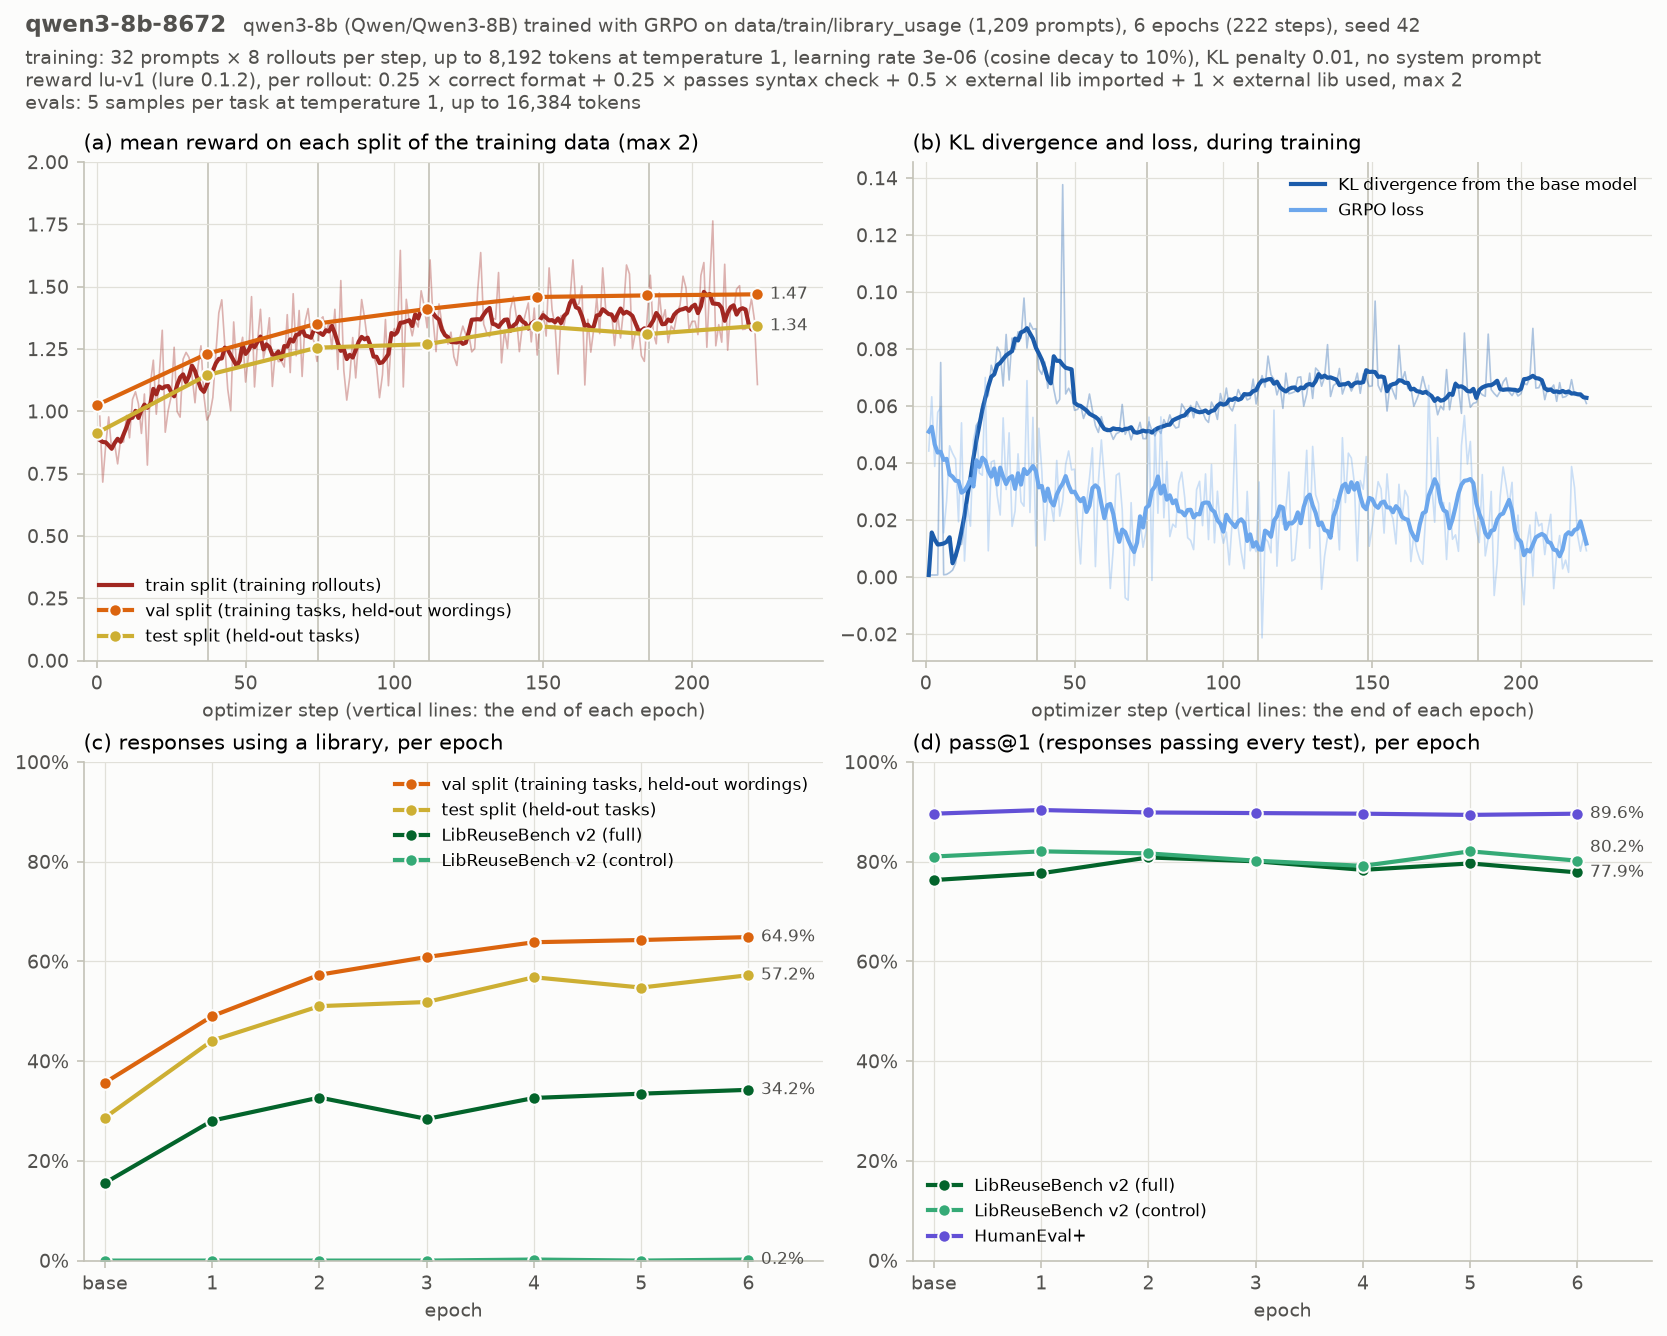

In [7]:
fig, axes = plt.subplots(
    2,
    2,
    figsize=(11, 8),
    dpi=150,
    layout="constrained",
)
(reward_ax, kl_ax), (library_ax, pass_ax) = axes

# (a): reward on each split of the training data - training rollouts at every step, the
# held-out splits at each epoch's checkpoint (the step where that epoch ends)
plot_steps(
    ax=reward_ax,
    values=train_df["reward"],
    colour=TRAINING_COLOUR,
    label=TRAINING_LABEL,
)
reward_ends = [
    plot_checkpoints(
        ax=reward_ax,
        dataset=dataset,
        values=held_out_rewards[dataset],
        x_scale=STEPS_PER_EPOCH,
    )
    for dataset in HELD_OUT_SPLITS
]
reward_ax.set_ylim(0, MAX_REWARD)
reward_ax.set_title(
    f"(a) mean reward on each split of the training data (max {MAX_REWARD:g})"
)
label_ends(ax=reward_ax, values=reward_ends, x_end=LAST_STEP, percent=False)

# (b): kl divergence and loss, per step (similar sizes, so one axis fits both)
plot_steps(
    ax=kl_ax,
    values=train_df["kl"],
    colour=KL_COLOUR,
    label="KL divergence from the base model",
)
plot_steps(
    ax=kl_ax,
    values=train_df["loss"],
    colour=LOSS_COLOUR,
    label="GRPO loss",
)
kl_ax.set_title("(b) KL divergence and loss, during training")

for ax in [reward_ax, kl_ax]:
    draw_epoch_ends(ax)
    ax.set_xlim(-0.02 * LAST_STEP, 1.1 * LAST_STEP)  # room on the right for end labels
    ax.set_xlabel("optimizer step (vertical lines: the end of each epoch)")

# (c): library use, from the training data's held-out splits out to the benchmark
library_ends = [
    plot_checkpoints(
        ax=library_ax,
        dataset=dataset,
        values=eval_values(dataset=dataset, metric="uses a library"),
    )
    for dataset in HELD_OUT_SPLITS + LIBREUSEBENCH_SETS
]
library_ax.set_ylim(0, 1)
library_ax.set_title("(c) responses using a library, per epoch")
label_ends(ax=library_ax, values=library_ends, x_end=FINAL_EPOCH)

# (d): is the code still correct, on the benchmark and on general coding tasks?
pass_ends = [
    plot_checkpoints(
        ax=pass_ax,
        dataset=dataset,
        values=eval_values(dataset=dataset, metric="pass@1"),
    )
    for dataset in LIBREUSEBENCH_SETS + REGRESSION_SETS
]
pass_ax.set_ylim(0, 1)
pass_ax.set_title("(d) pass@1 (responses passing every test), per epoch")
label_ends(ax=pass_ax, values=pass_ends, x_end=FINAL_EPOCH)

for ax in [library_ax, pass_ax]:
    ax.set_xticks(list(EPOCH_DIRS), labels=map(epoch_label, EPOCH_DIRS))
    ax.set_xlim(-0.2, FINAL_EPOCH + 0.7)  # room on the right for end labels
    ax.set_xlabel("epoch")
    percent_axis(ax.yaxis)

# a legend in each panel, wherever it covers the fewest points, so each panel reads on
# its own. a colour means the same thing in every panel
for ax in axes.flat:
    ax.legend(loc="best")

# the header above the panels: the run's name in bold, then how it was trained,
# rewarded and evaluated. it sits just above the figure's top edge, and is kept in the
# saved file because savefig's bbox_inches="tight" takes in everything drawn
final_decoding = eval_df[eval_df["epoch"] == FINAL_EPOCH]["decoding"].iloc[0]
eval_line = (
    f"evals: {final_decoding['n_samples']} samples per task at temperature "
    f"{final_decoding['temperature']:g}, up to {final_decoding['max_new_tokens']:,} tokens"
)
header_text = {"color": INK, "fontsize": 9}
header = VPacker(
    children=[
        HPacker(
            children=[
                TextArea(
                    RUN_ID,
                    textprops={**header_text, "fontsize": 11, "fontweight": "bold"},
                ),
                TextArea(RUN_LINE, textprops=header_text),
            ],
            align="baseline",
            pad=0,
            sep=8,
        ),
        TextArea(
            "\n".join([TRAINING_LINE, REWARD_LINE, eval_line]),
            textprops=header_text,
        ),
    ],
    align="left",
    pad=0,
    sep=5,
)
fig.add_artist(
    AnchoredOffsetbox(
        loc="lower left",
        child=header,
        bbox_to_anchor=(0.01, 1.01),
        bbox_transform=fig.transFigure,
        frameon=False,
        pad=0,
        borderpad=0,
    )
)

fig.savefig(SUMMARY_FILE, dpi=200, bbox_inches="tight")
print(f"saved: {SUMMARY_FILE}")
plt.show()